# Practical 4: Logistic Regression - Diabetes Prediction

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Compact_Logistic_Regression_Diabetes_Dr_Priya_Pandharbale.ipynb`

**A. Aim:** Train Logistic Regression for binary classification and plot the sigmoid function, decision boundary and ROC curve with AUC (Pima Indians Diabetes dataset).

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install pandas numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* pandas, numpy, matplotlib, scikit-learn (internet needed once to download the CSV)

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Compact_Logistic_Regression_Diabetes_Dr_Priya_Pandharbale.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression – Diabetes Prediction



**Aim:** Train Logistic Regression for binary classification and plot the sigmoid function, decision boundary and ROC curve with AUC.

**Author: Dr. Priya B. Pandharbale**

Dataset: Pima Indians Diabetes (Kaggle). `Outcome`: 0 = Non-diabetic, 1 = Diabetic.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

## 1. Load and prepare the data

In [2]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0     30.5  33.6   
1            1     85.0           66.0           29.0     30.5  26.6   
2            8    183.0           64.0           23.0     30.5  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


## 2. Train the Logistic Regression model

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7077922077922078


## 3. Sigmoid function

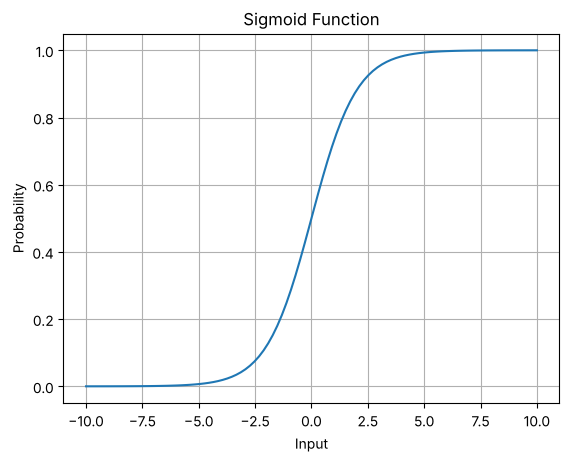

In [4]:
z = np.linspace(-10, 10, 100)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.title("Sigmoid Function")
plt.xlabel("Input"); plt.ylabel("Probability")
plt.grid(); plt.show()

## 4. Decision boundary

Use Glucose and BMI to draw a simple 2D decision boundary. The main model above uses all eight features.

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


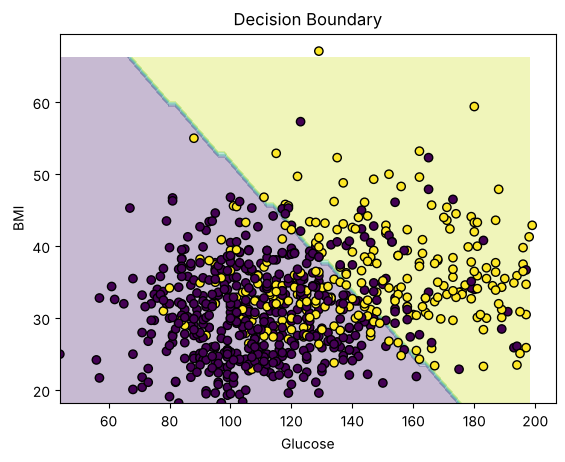

In [5]:
X2 = df[["Glucose", "BMI"]]
a, b = np.meshgrid(
    np.arange(X2.Glucose.min(), X2.Glucose.max(), 2),
    np.arange(X2.BMI.min(), X2.BMI.max(), 1))

sc2 = StandardScaler()
X2_scaled = sc2.fit_transform(X2)
m2 = LogisticRegression().fit(X2_scaled, y)

grid = sc2.transform(np.c_[a.ravel(), b.ravel()])
pred = m2.predict(grid).reshape(a.shape)

plt.contourf(a, b, pred, alpha=0.3)
plt.scatter(X2.Glucose, X2.BMI, c=y, edgecolors="k")
plt.xlabel("Glucose"); plt.ylabel("BMI")
plt.title("Decision Boundary"); plt.show()

## 5. ROC curve and AUC

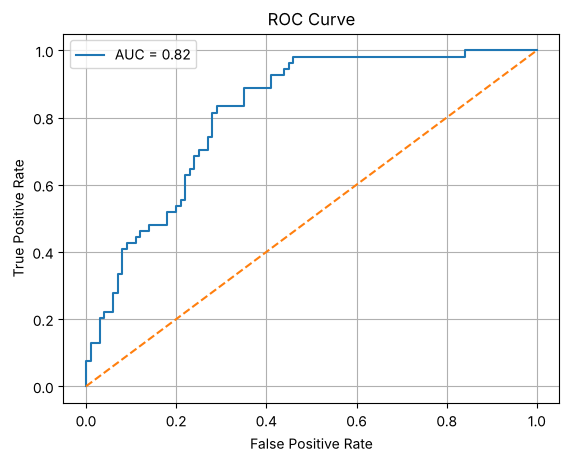

AUC: 0.8151851851851852


In [6]:
prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, prob)
score = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = %.2f" % score)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.grid(); plt.show()
print("AUC:", score)

## Observations
1. Logistic Regression predicts diabetic (1) or non-diabetic (0).
2. The sigmoid function converts model scores into probabilities between 0 and 1.
3. The decision boundary separates the two classes using Glucose and BMI.
4. The ROC curve compares true-positive and false-positive rates at different thresholds.
5. AUC closer to 1 indicates better separation of the two classes.

## Result
Logistic Regression was trained on the diabetes dataset. The sigmoid function, decision boundary and ROC curve were plotted, and AUC was calculated.

*This is a classroom exercise, not a medical diagnostic tool.*

---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - Different train/test split + classify a new patient

**Changed input:** `test_size=0.2` -> `0.3` in Section 2; new patient added

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #3 (section *2. Train the Logistic Regression model*).

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0     30.5  33.6   
1            1     85.0           66.0           29.0     30.5  26.6   
2            8    183.0           64.0           23.0     30.5  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Accuracy: 0.7532467532467533
New patient -> predicted class: 1 | P(diabetic) = 0.553


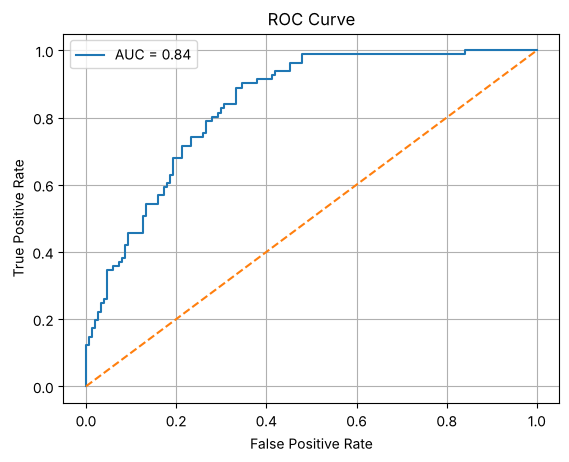

AUC: 0.8374485596707818


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print(df.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)  # <-- CHANGED (original: X, y, test_size=0.2, random_state=42, stratify=y))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

# ADDED: classify a new patient
# order: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
new_patient = pd.DataFrame([[2, 150, 80, 35, 100, 35.0, 0.5, 45]], columns=X.columns)
new_scaled = scaler.transform(new_patient)
print("New patient -> predicted class:", model.predict(new_scaled)[0],
      "| P(diabetic) =", round(model.predict_proba(new_scaled)[0, 1], 3))

prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, prob)
score = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = %.2f" % score)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.grid(); plt.show()
print("AUC:", score)

**Actual output explained**

**What changed:** 30 % of the data is now used for testing. Accuracy rose from 0.7078 to **0.7532**, AUC from 0.8152 to **0.8374**. The new patient (2 pregnancies, glucose 150, BP 80, skin 35, insulin 100, BMI 35, pedigree 0.5, age 45) is predicted **class 1 (diabetic) with probability 0.553**.

**Why:** a different, larger test set; the numbers change because the model is evaluated on different patients. 0.553 is just above the 0.5 threshold, so the prediction is 'diabetic' but with low confidence.

### E. Input Experiment 2 - Stronger regularisation

**Changed input:** `LogisticRegression()` -> `LogisticRegression(C=0.01)` in Section 2

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #3 (section *2. Train the Logistic Regression model*).

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0     30.5  33.6   
1            1     85.0           66.0           29.0     30.5  26.6   
2            8    183.0           64.0           23.0     30.5  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Accuracy: 0.7402597402597403
Coefficients with C=0.01 : [[0.178 0.541 0.076 0.098 0.059 0.305 0.131 0.152]]
Coefficients with C=1.0  : [[ 0.376  1.209 -0.054  0.029 -0.133  0.701  0.245  0.138]] (default, for comparison)


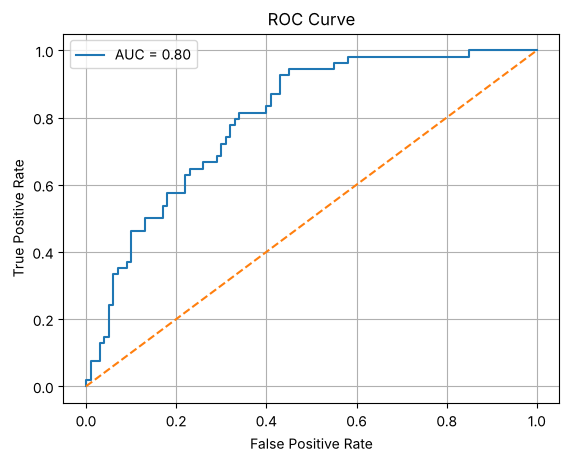

AUC: 0.7975925925925926


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print(df.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(C=0.01)  # <-- CHANGED (original: model = LogisticRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Coefficients with C=0.01 :", model.coef_.round(3))   # ADDED line

print("Coefficients with C=1.0  :", LogisticRegression().fit(X_train, y_train).coef_.round(3), "(default, for comparison)")   # ADDED line

prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, prob)
score = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = %.2f" % score)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.grid(); plt.show()
print("AUC:", score)

**Actual output explained**

**What changed:** `C = 0.01` (default is 1.0). Accuracy **0.7403** (was 0.7078), AUC **0.7976** (was 0.8152). The coefficients shrank, e.g. Glucose 1.209 -> 0.541 and BMI 0.701 -> 0.305.

**Why:** `C` is the inverse of regularisation strength. A small `C` applies a strong L2 penalty that pulls all weights towards zero, giving a simpler model. Here accuracy happened to rise slightly while AUC fell slightly - regularisation does not always help or hurt.

### F. Input Experiment 3 - Different features for the 2-D decision boundary

**Changed input:** `["Glucose","BMI"]` -> `["Age","BMI"]` in Section 4

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #5 (section *4. Decision boundary*).

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0     30.5  33.6   
1            1     85.0           66.0           29.0     30.5  26.6   
2            8    183.0           64.0           23.0     30.5  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


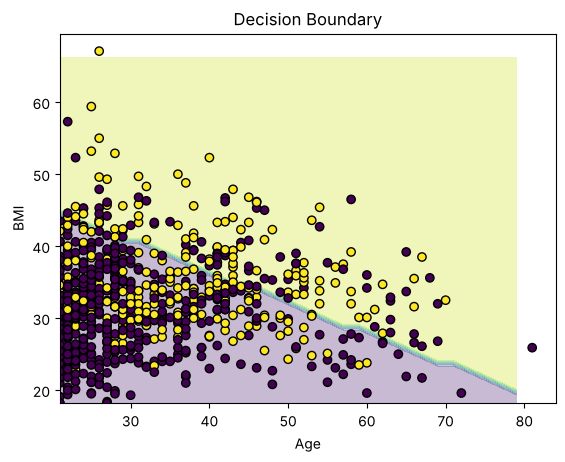

2-feature model accuracy on all data: 0.6848958333333334
Glucose+BMI model accuracy on all data (original features): 0.7643229166666666


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print(df.head())

X2 = df[["Age", "BMI"]]  # <-- CHANGED (original: X2 = df[["Glucose", "BMI"]])
a, b = np.meshgrid(
    np.arange(X2.Age.min(), X2.Age.max(), 2),  # <-- CHANGED (original: np.arange(X2.Glucose.min(), X2.Glucose.max(), 2),)
    np.arange(X2.BMI.min(), X2.BMI.max(), 1))

sc2 = StandardScaler()
X2_scaled = sc2.fit_transform(X2)
m2 = LogisticRegression().fit(X2_scaled, y)

grid = sc2.transform(np.c_[a.ravel(), b.ravel()])
pred = m2.predict(grid).reshape(a.shape)

plt.contourf(a, b, pred, alpha=0.3)
plt.scatter(X2.Age, X2.BMI, c=y, edgecolors="k")  # <-- CHANGED (original: plt.scatter(X2.Glucose, X2.BMI, c=y, edgecolors="k"))
plt.xlabel("Age"); plt.ylabel("BMI")  # <-- CHANGED (original: plt.xlabel("Glucose"); plt.ylabel("BMI"))
plt.title("Decision Boundary"); plt.show()

print("2-feature model accuracy on all data:", m2.score(X2_scaled, y))   # ADDED line

sc_gb = StandardScaler(); Xgb = sc_gb.fit_transform(df[["Glucose", "BMI"]])   # ADDED line (baseline for comparison)

print("Glucose+BMI model accuracy on all data (original features):", LogisticRegression().fit(Xgb, y).score(Xgb, y))   # ADDED line

**Actual output explained**

**What changed:** the 2-D boundary now uses **Age and BMI** instead of Glucose and BMI. The accuracy of this 2-feature model on all data is **0.6849**, versus **0.7643** for the original Glucose + BMI model.

**Why:** Glucose is a much stronger predictor of diabetes than Age, so the Age + BMI boundary separates the classes less well and the picture shows more overlap. The line is also tilted differently because the model weights Age and BMI differently.

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. What is the sigmoid function and why is it used?**  
sigma(z) = 1/(1 + e^-z). It maps any real number to (0, 1), so the model output can be read as a probability. sigma(0) = 0.5.

**Q2. Why is it called 'regression' if it does classification?**  
It fits a linear model to the log-odds (logit) of the outcome; the sigmoid converts that to a probability, and a threshold (0.5) turns the probability into a class.

**Q3. Why is StandardScaler fitted only on the training data?**  
To avoid data leakage: the test set must not influence the scaling. Scaling also helps the solver converge and makes regularisation treat features fairly.

**Q4. Why are zeros replaced by the median for Glucose, BloodPressure, etc.?**  
A value of 0 is physiologically impossible for these columns, so it means 'missing'. (Note: in this notebook the median is computed on the whole data before the split - a mild leakage.)

**Q5. What are the ROC curve and AUC?**  
ROC plots true-positive rate against false-positive rate for every threshold. AUC is the area under it: 0.5 = random guessing, 1.0 = perfect. The original model has AUC 0.815.

**Q6. What does the parameter C do?**  
C is the inverse of regularisation strength. Smaller C = stronger penalty = smaller coefficients (Experiment 2).

**Q7. Is the decision boundary of logistic regression linear?**  
Yes. It is the set of points where w.x + b = 0, i.e. probability exactly 0.5.

---
## Common errors and solutions (ADDED)

- `URLError` / `HTTPError` when reading the CSV -> no internet. Download `diabetes.csv` manually and use `pd.read_csv('diabetes.csv')`.
- `UserWarning: X does not have valid feature names` -> harmless warning (the grid is a NumPy array).
- `ConvergenceWarning` -> increase `max_iter`, e.g. `LogisticRegression(max_iter=1000)`.